# Full example


Here, we show a full example analysis of PathoPlex spatial proteomics data with `spatiomic`. To avoid version conflicts, we recommend installing the package in a fresh virtual environment. Installing in a new environment may take a couple of minutes as common dependencies are installed. Caution: The minimum Python requirement is 3.11.


`pip install -q spatiomic`


In addition, installation of `session_info2` and `requests` (e.g., via pip) is necessary to run this notebook: `pip install -q session_info2 requests`


In [1]:
from logging import ERROR, getLogger
from warnings import filterwarnings

In [2]:
getLogger("matplotlib.font_manager").setLevel(ERROR)
filterwarnings("ignore", category=UserWarning)
filterwarnings("ignore", category=FutureWarning)

In [3]:
from time import time as get_time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from colorcet import linear_kryw_5_100_c67
from matplotlib.colors import ListedColormap
from session_info2 import session_info
from skimage.transform import downscale_local_mean
from tqdm import tqdm

import spatiomic as so

We will time how long it takes to run this notebook. The self-organizing map is trained on a GPU if one is available, with CUDA on NVIDIA GPUs or MPS on Apple silicon, and on the CPU otherwise. The other steps of this example run on the CPU. With a CUDA-enabled GPU, many other `spatiomic` functions can be accelerated as well: install the RAPIDS.ai dependencies as described in the installation instructions and set `use_gpu` to `True` in their calls.

In [4]:
time_start = get_time()

## Data loading


We will work with a subsample of fields-of-view acquired through a controlled PathoPlex spatial proteomics experiment. Here, murine kidney biopsies from mice with crescentic glomerulonephritis (an immune-mediated kidney disease) a compared to healthy control biopsies. Note that the images have already been registered. If you have cyclically acquired images with an offset between cycles, you will need to register them first. Please refer to the registration tutorial.


In [5]:
images = [
    "245 g1",
    "245 g2",
    "247 g2",
    "247 g4",
    "248 g2",
    "248 g4",
    "263 g2",
    "263 g4",
    "265 g2",
    "265 g3",
    "266 g4",
    "266 g5",
]
samples = [image.split(" ")[0] for image in images]
is_disease = [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0]

If the data is not available locally, example data can be downloaded from `data.complextissue.com`. This requires the additional installation of the `requests` package and about 3 GB of free disk space.


In [6]:
import os
from warnings import warn

from requests import get

base_url = "https://data.complextissue.com/spatiomic/tutorial/data/"


def download_file(url, output_path):
    """Download file from URL to output path."""
    response = get(url, stream=True, timeout=10)
    total_size = int(response.headers.get("content-length", 0))
    block_size = 1024

    if os.path.exists(output_path):
        warn(f"File already exists: {output_path}")
        response.close()
        return

    with (
        open(output_path, "wb") as file,
        tqdm(
            total=total_size,
            unit="iB",
            unit_scale=True,
            unit_divisor=1024,
            leave=False,
            desc=f"Downloading {output_path}",
        ) as bar,
    ):
        for data in response.iter_content(block_size):
            bar.update(len(data))
            file.write(data)

    # Check that the size of the downloaded file is correct
    if total_size != 0 and bar.n != total_size:
        os.remove(output_path)
        raise ValueError(f"Downloaded file is incorrect and has been removed: {output_path}. Please try again.")


os.makedirs("./data", exist_ok=True)
os.makedirs("./data/mouse_cgn", exist_ok=True)

for image in images:
    download_file(f"{base_url}{image}.tif", f"./data/mouse_cgn/{image}.tif")
download_file(f"{base_url}channel_names.csv", "./data/mouse_cgn/channel_names.csv")

We still have "DAPI" and "DRAQ5" (two nuclear markers) in the data. Since one is sufficient and DRAQ5 has better contrast, let's remove DAPI.


In [7]:
channels_data = list(pd.read_csv("./data/mouse_cgn/channel_names.csv", header=0).T.to_numpy()[0])
channels = sorted([channel for channel in channels_data if "DAPI" not in channel])

Now, let's load in the actual data. First, we read in each image, next we downscale it for this example notebook. In a real-world scenario, you would not downscale the images. Then, we filter the channels to the subset them to the desired channels and finally we subsample random pixels from each image to train our clustering algorithm on.


In [8]:
img_data = []
subsamples = []

for image in tqdm(images):
    # read the image and convert the dimension order to XYC/channel-last
    data = so.data.read().read_tiff(
        f"./data/mouse_cgn/{image}.tif",
        input_dimension_order="CYX",
    )

    # for the example, we downscale the image 4-fold (2 x 2 pixels) to keep the run time short
    data = downscale_local_mean(data, factors=(2, 2, 1))

    # subset the channels
    data = so.data.subset(
        data,
        channel_names_data=channels_data,
        channel_names_subset=channels,
    )

    # create a random subsample of 40000 pixels per image
    subsample = so.data.subsample().fit_transform(
        data,
        method="count",  # you can also use "fraction"
        count=150000,  # or fraction=0.1,
        seed=0,
    )

    img_data.append(data)
    subsamples.append(subsample)

subsample = np.concatenate(subsamples, axis=0)
len(img_data), img_data[0].shape, subsample.shape

100%|██████████| 12/12 [00:07<00:00,  1.61it/s]


(12, (875, 875, 34), (1800000, 34))

For larger datasets, we recommend getting a weighted subsample from all images. This enables you to stay within the memory limit of your system while making sure that the data is representative of the entire dataset. Once the preprocessing classes have been fitted on the subsample, they can be applied to the entire dataset on an image-by-image basis. When working with a real-world dataset, you might want to control for multiple variables, such as the experimental conditions, the sample count per condition, the number of FOVs per sample or multiple imaging plates. In such a case, we recommend calculating the subsample size for each image beforehand.


## Data preprocessing


Available preprocessing classes include `clip` for histogram clipping, `normalize` for normalizing images to a specific range and `zscore` for z-scoring images, among others. Using `normalize` facilitates interpretability while the `zscore` class ensures that all channels have a similar influence. We usually use `clip` in combination with `normalize`.


When all signals are well represented in a relevant part of the dataset with specific signals, performing histogram clipping based on percentiles can be useful and very quick. The lower value should be chosen to lie surely outside the portion of the data covered by specific signals and the upper threshold should surely represent specific signal.


In [9]:
clipper = so.process.clip(
    method="percentile",
    percentile_min=50.0,  # assuming no marker covers more than 50% of the image with any specific signal
    percentile_max=99.95,  # assuming no marker covers less than 0.05% of the image with high-intensity specific signal
    use_gpu=False,
)

However, sometimes there might be markers that have very low abundance of specific signal in the dataset. If you don't want to exclude such markers, manually evaluating reasonable histogram thresholds based on a number of images is recommended. You can also easily combine the percentile-based and the absolute value-based approaches.


In [10]:
low_abundance_markers = [
    # Add if needed
]

min_values, max_values = np.percentile(subsample, [75.0, 99.95], axis=0)
max_values[np.isin(channels, low_abundance_markers)] = 100

clipper = so.process.clip(
    method="minmax",
    min_value=min_values,
    max_value=max_values,
    use_gpu=False,
)

In [11]:
normalizer = so.process.normalize(
    min_value=0.0,
    max_value=1.0,
    use_gpu=False,
)

We first apply `fit_transform` on the subsample, to configure the classes to be representative of the subsample and thus all images.


In [12]:
# clip the data to defined percentiles, channel-wise
subsample_processed = clipper.fit_transform(subsample)

# normalize the data to a range between 0 and 1, channel-wise
subsample_processed = normalizer.fit_transform(subsample_processed)

We can then apply the preprocessing to each image in the dataset individually using the `transform` method.


In [13]:
img_data_processed = []

for image, image_name in zip(img_data, images):
    image = clipper.transform(image)
    image = normalizer.transform(image)
    np.save(f"./data/mouse_cgn/{image_name}.npy", image)

    img_data_processed.append(image)

You can use the `plot` submodule to view the individual channels of an image.


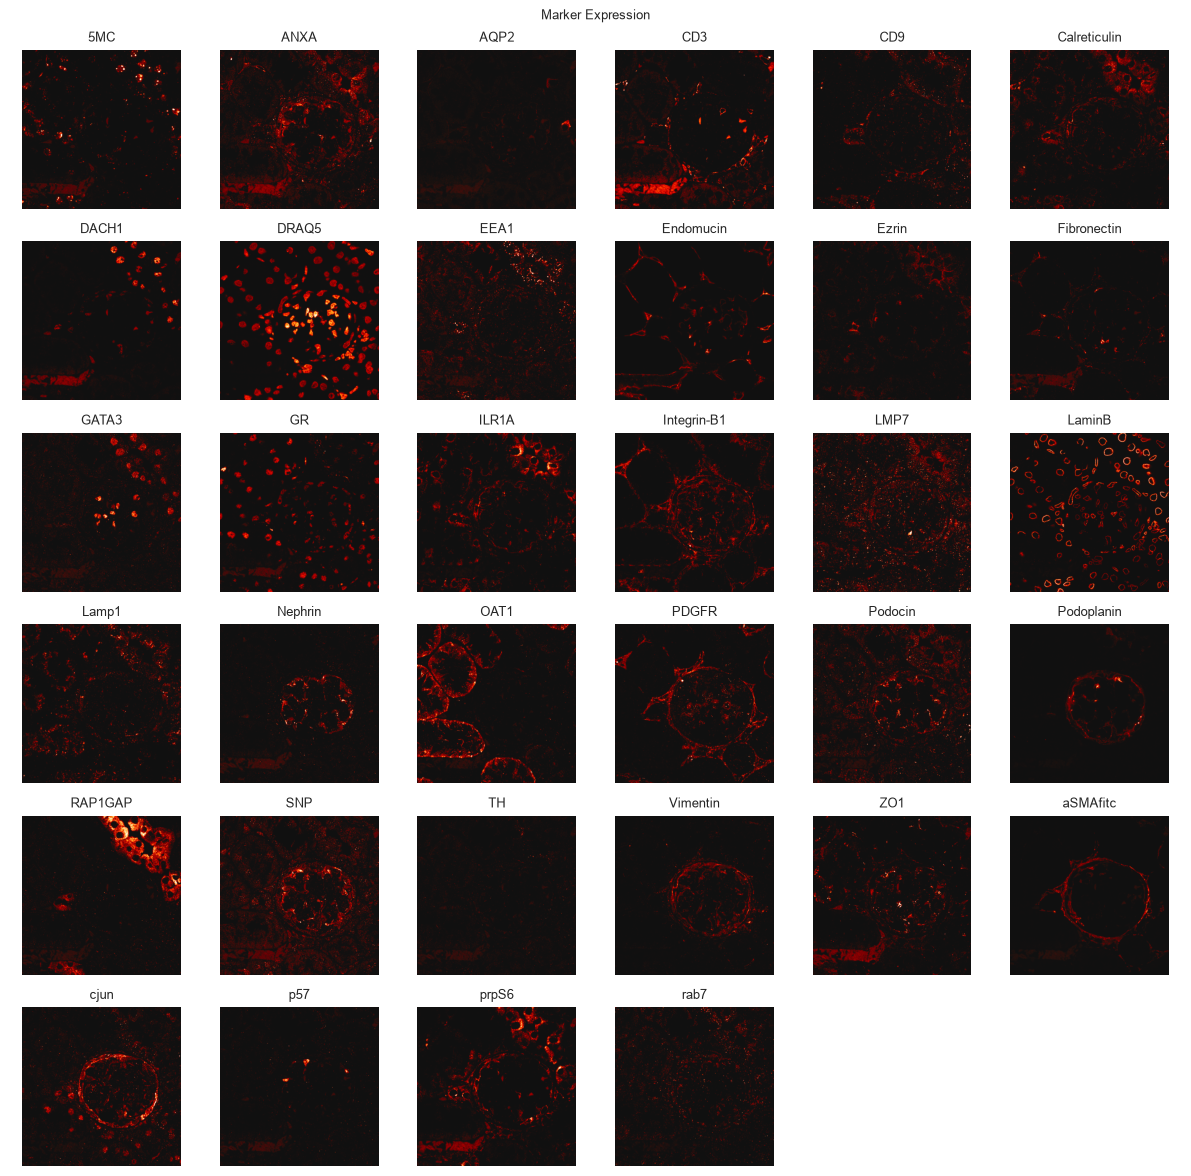

In [14]:
fig = so.plot.marker_expression(
    img_data_processed[0],
    channel_names=channels,
    max_value=1.0,
    figsize=(12, 12),
    colormap=ListedColormap(linear_kryw_5_100_c67),
)

## Self-organizing map training


Even with a subsample, graph clustering would be computationally very slow. If the subsample was clustered directly, rarer signals might also get grouped together with more abundant signals in the neighborhood graph. We therefore first train a self-organizing map to get a dimensionality-reduced representation of the data. This representation can then be used to identify clusters in the data. The number of SOM nodes will determine how many different co-expression signatures can be learned well. For real world datasets, we commonly use values between (100, 100) and (500, 500) with GPU acceleration.


In [15]:
img_data_som = so.dimension.som(
    node_count=(150, 150),
    dimension_count=subsample_processed.shape[-1],
    distance_metric="euclidean",  # or "cosine" or "correlation" (Pearson)
    use_gpu=True,
    seed=0,
    verbose=True,  # show a progress bar while fitting
    deterministic=True,  # the same map in every run on the GPU, at the cost of speed
)

In [16]:
img_data_som.fit(
    subsample_processed,
    iteration_count=10,  # We recommend to start with about 10 and to evaluate the quantization error to determine if more iterations are needed
)
img_data_som.save("./data/mouse_cgn/example_map.p")

Fitting SOM: 100%|██████████| 10/10 [00:32<00:00,  3.21s/epoch]


You can easily evaluate how well your SOM fits the training data by plotting the distances (here, Euclidean distance) from each data point in the subsample to its corresponding SOM node. What values are considered "good" will depend on the average intensity in your dataset, the number of markers and the distance metric you use. We encourage you to evaluate multiple SOM sizes with few iterations first and once you have identified the approximate size for a SOM that can fit your data well to then train it for more iterations.


In [17]:
quantization_error, distances = img_data_som.get_quantization_error(subsample_processed, return_distances=True)

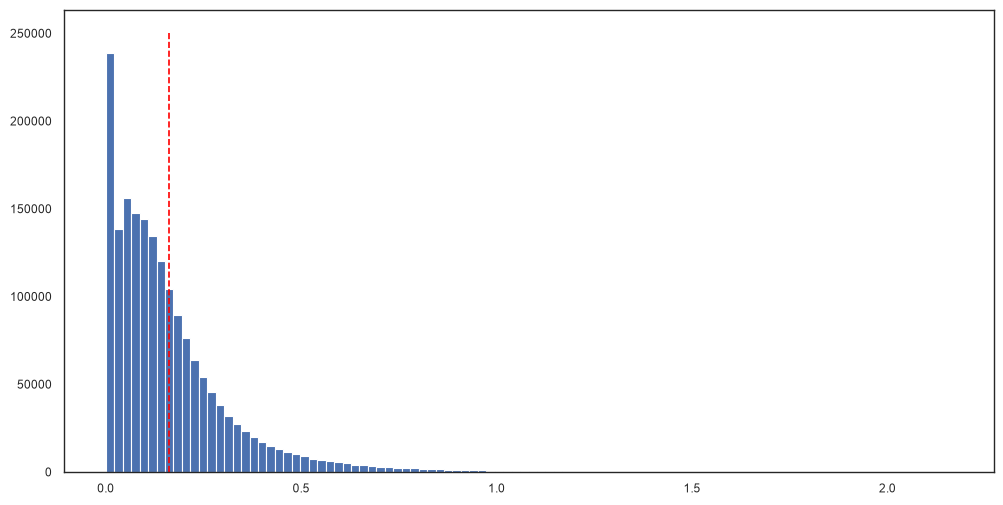

In [18]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(
    distances,
    bins=100,
)
ax.vlines(
    quantization_error,
    ymin=0,
    ymax=ax.get_ylim()[1],
    color="red",
    linestyle="--",
)

As a quality control of SOM-fitting, we can examine which SOM nodes express which markers. Spatially co-expressed markers should be closer to each other in the SOM space.


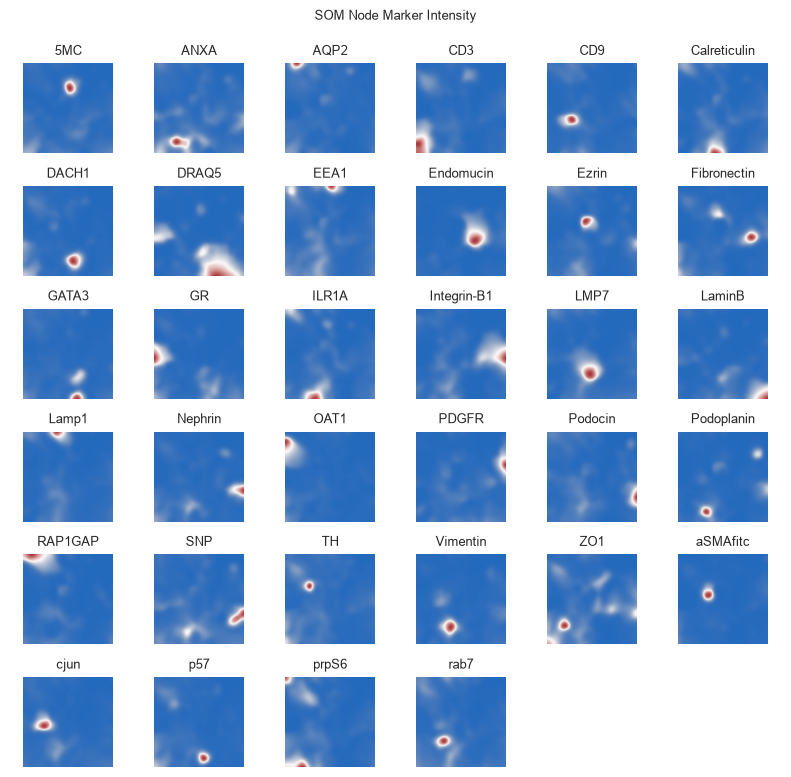

In [19]:
fig = so.plot.som_marker_expression(
    img_data_som.get_nodes(flatten=False),
    figsize=(8, 8),
    channel_names=channels,
)

## Cluster the SOM nodes


To identify pixel clusters of protein co-expression, we use similarity-based graph clustering with Leiden.


In [20]:
# create a k nearest neighbor graph
knn_graph_som = so.neighbor.knn_graph().create(
    img_data_som,
    neighbor_count=50,
    use_gpu=False,
)

In [21]:
# perform Leiden clustering
communities, modularity = so.cluster.leiden().predict(
    knn_graph_som,
    resolution=1.4,
    iteration_count=5,
    seed=42,
    use_gpu=False,
)

In [22]:
len(np.unique(communities)), modularity

(32, 0.8798614581769142)

It can be difficult to evaluate which cluster resolution is best based on the modularity alone, as it is not really comparable between resolutions. It's best practice to check whether your clustering approach can identify expected co-expression patterns by running the subsequent steps. You may also want to use a tool like [pyclustree](https://pyclustree.complextissue.com/stable/example.html) to evaluate different resolutions.


To visualize the clusters, we first need a colormap. For fewer than 100 clusters, we can use the `glasbey_light` colormap from `colorcet`, else we can randomly generate one (set `flavor` to `random_hls` and specify a `seed`). We can always override individual colors in the colormap, e.g., to color background clusters black.


In [23]:
# get the som node with the smallest mean intensity
background_node = np.argmin(np.mean(img_data_som.get_nodes(), axis=1))
background_cluster = communities[background_node]

colormap = so.plot.colormap(
    color_count=np.max(communities) + 1,
    flavor="random_hls",
    seed=42,
    color_override={
        background_cluster: "#000000",  # set the empty background to black
    },
)

We can visually inspect the clusters for the SOM nodes as they are arranged within the self-organizing map.


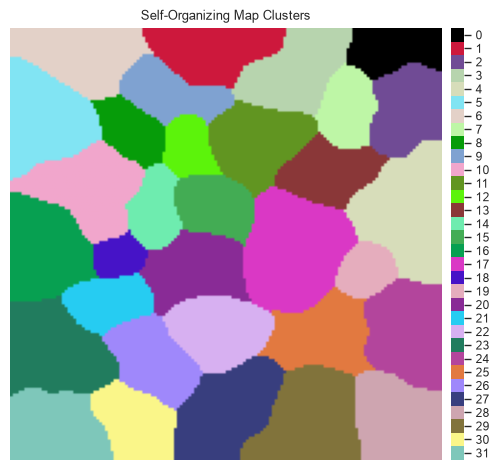

In [24]:
fig = so.plot.som_clusters(img_data_som, communities, colormap=colormap)

## Cluster composition


The composition of the clusters can either be calculated from the representative SOM nodes or from randomly sampled clustered images. The former allows you to just the clustering before applying it to the entire dataset, enabling quicker iterations. The latter represents the dataset slightly more accurately, but is computationally more expensive and generally similar to the representative SOM nodes.


In [25]:
df_stats = so.tool.get_stats(
    img_data_som.get_nodes(),
    group=communities,
    channel_names=channels,
    comparison="all",
    test="t",
    permutation_count=1000,  # Setting permutation count will perform a permutation test with the "test" statistic
    equal_variance=False,
    dependent=False,
    correction="fdr",
)

From a previous analysis, we know that there is a cluster that has an increased phospho-c-Jun expression in PECs (an effector cell type in crescentic glomerulonephritis), so let's try to find it.


In [26]:
df_stats_cjun = df_stats[df_stats["marker"] == "cjun"].sort_values("mean_group", ascending=False).head(2)
df_stats_cjun

,group,comparison,marker,p_value_corrected,log10_p_value_corrected,mean_group,mean_comparison,p_value,log10_p_value,ranksum,log2_fold_change
642,18,all,cjun,0.002129,2.671801,0.411166,0.018361,0.001998,2.699404,None,4.485003
574,16,all,cjun,0.002129,2.671801,0.068692,0.020516,0.001998,2.699404,None,1.743413


You can then plot the contributors for each cluster with their mean intensity, log2 fold change and p-value. The p-value is not shown on the axis but color-coded.


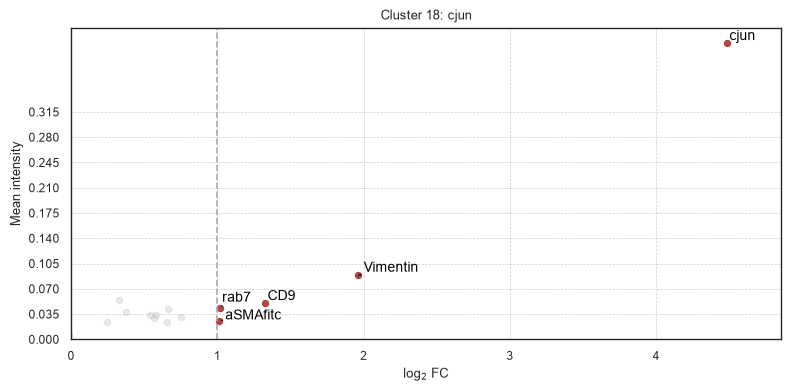

In [27]:
fig = so.plot.cluster_contributors(
    df_stats,
    cluster_idx=df_stats_cjun["group"].to_numpy()[0],
    increased_log2_fold_change_threshold=1,
    log10_p_value_column="log10_p_value_corrected",
    mean_max=0.35,
    figsize=(8, 4),
    title=f"Cluster {df_stats_cjun['group'].to_numpy()[0]}: {df_stats_cjun['marker'].to_numpy()[0]}",
)
fig.set_dpi(100)

We can also get the mean intensity of all markers for each cluster as a table.


In [28]:
df_cluster_marker_intensity = so.tool.mean_cluster_intensity(
    img_data_som.get_nodes(),
    clusters=communities,
    channel_names=channels,
)
df_cluster_marker_intensity.head()

,5MC,ANXA,AQP2,CD3,CD9,Calreticulin,DACH1,DRAQ5,EEA1,Endomucin,...,RAP1GAP,SNP,TH,Vimentin,ZO1,aSMAfitc,cjun,p57,prpS6,rab7
0,0.001183,0.000694,0.000942,0.000536,0.002496,0.000462,0.000647,0.000700,0.000598,0.001084,...,0.000578,0.001409,0.000816,0.001101,0.000257,0.003196,0.001467,0.000536,0.000478,0.000528
1,0.008178,0.009901,0.004530,0.015384,0.015262,0.025484,0.007626,0.006729,0.076487,0.002937,...,0.029009,0.011190,0.008629,0.006897,0.011546,0.004317,0.010246,0.009184,0.014240,0.026605
2,0.003345,0.009121,0.001880,0.002882,0.004668,0.005851,0.001881,0.003055,0.003566,0.003811,...,0.001836,0.013702,0.002414,0.012619,0.005131,0.005199,0.004825,0.002508,0.002957,0.003645
3,0.008223,0.006815,0.006272,0.033446,0.002575,0.002625,0.010284,0.002369,0.008990,0.001460,...,0.004353,0.006165,0.006002,0.001782,0.003840,0.003398,0.003549,0.008717,0.005950,0.006780
4,0.011300,0.017257,0.002372,0.014774,0.019661,0.022216,0.004512,0.012863,0.009230,0.023585,...,0.010182,0.011567,0.009140,0.014735,0.025353,0.013993,0.007744,0.006987,0.014563,0.009669


For a given cluster, we can plot a histogram of all the intensities of SOM nodes or pixels assigned to that cluster by marker. We again see that Vimentin, Podoplanin and phospho-c-Jun are highly expressed in this cluster and seem to be driving it, as no assigned SOM nodes have a low expression of these markers.


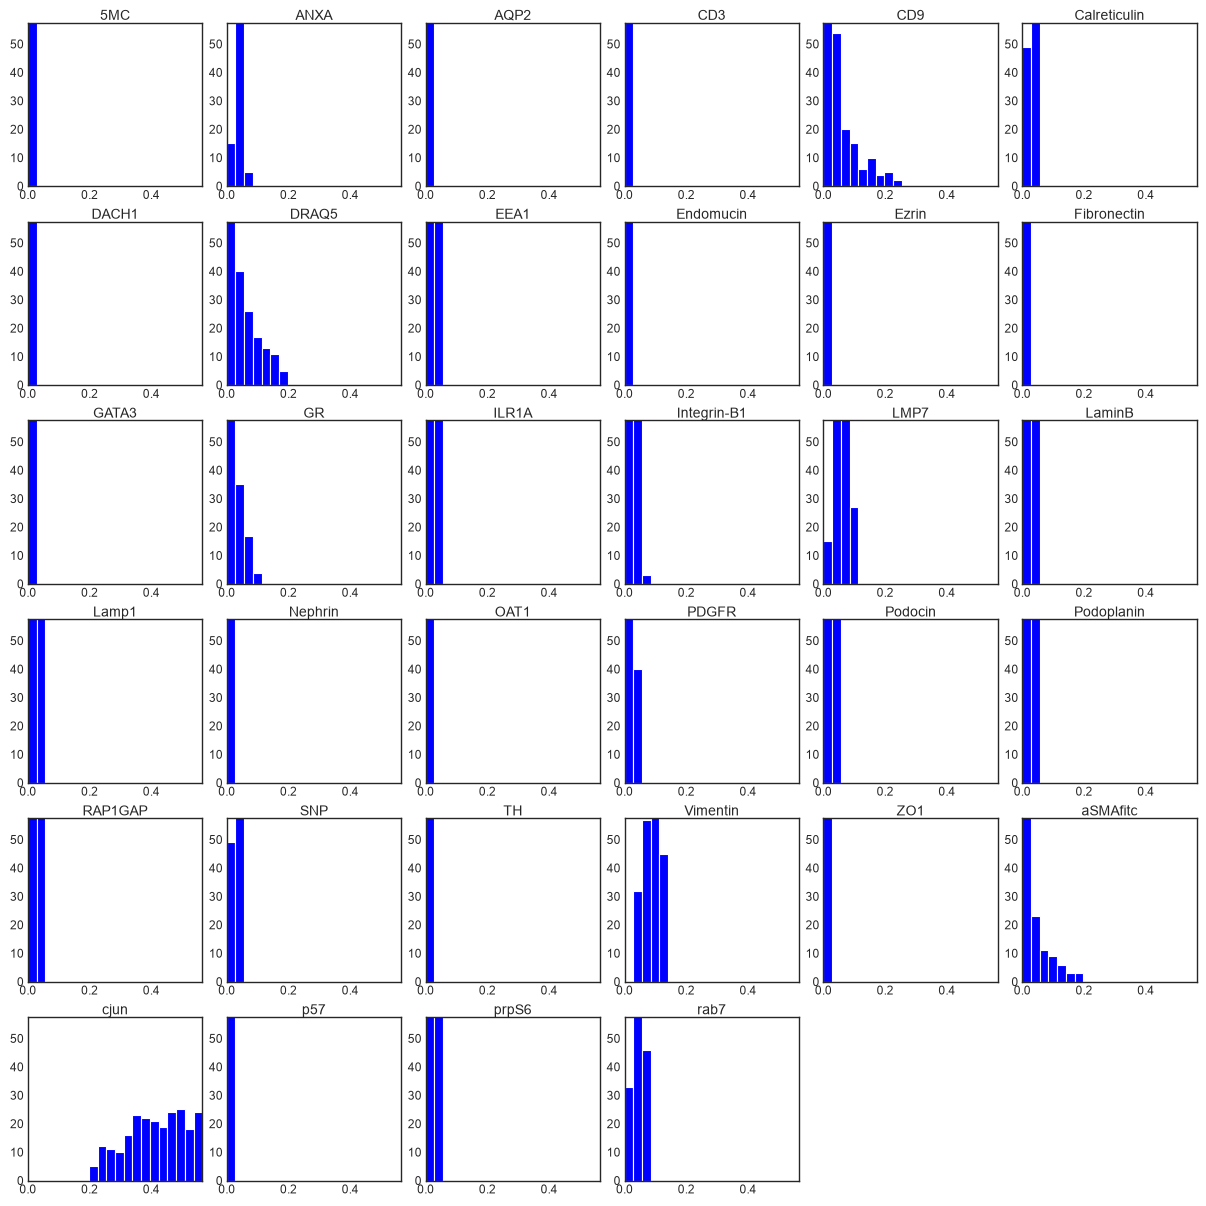

In [29]:
fig = so.plot.cluster_contributor_histogram(
    img_data_som.get_nodes()[np.array(communities) == df_stats_cjun["group"].to_numpy()[0]],
    channel_names=channels,
    bin_count=20,
    scaling_factor_y=0.2,  # play around with this value to adjust the y-axis scaling, smaller values zoom out
)

Phospho-c-Jun is involved in the AP-1 signalling cascade and has previously been indicated to play a role in crescentic glomerulonephritis, though its upregulation in PECs has not been profiled. However, to fully interpret this signal, we need to evaluate its expression in space. For this, we need to cluster all images in the dataset and perform differential abundance analysis as well as spatial projection.


## Clustering of entire images


In [30]:
for image, image_name in tqdm(zip(img_data_processed, images, strict=True)):
    clustered_image = img_data_som.label(
        image,
        communities,
        save_path=f"./data/mouse_cgn/{image_name}-labelled.npy",
    )

    so.plot.save_cluster_image(
        clustered_image,
        f"./data/mouse_cgn/{image_name}-labelled.png",
        colormap=colormap,
    )

12it [00:13,  1.15s/it]


You can view the cluster projection in space (shown in the downsampled example image, PathoPlex can provide higher resolution images).


In [31]:
labelled_image = np.load(f"./data/mouse_cgn/{images[0]}-labelled.npy")

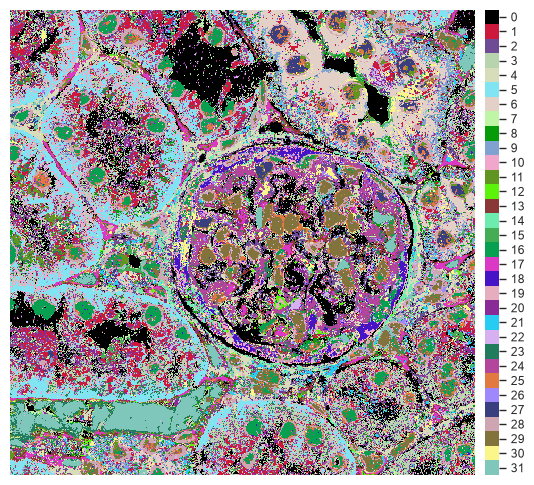

In [32]:
fig = so.plot.cluster_image(
    labelled_image,
    colormap=colormap,
)

It's always useful to get a legend for the cluster colors separately.


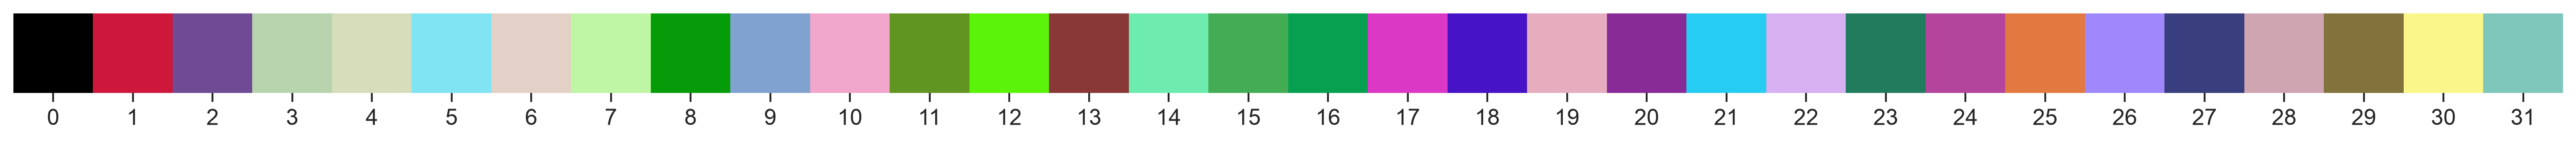

In [33]:
fig = so.plot.cluster_legend(
    cluster_count=np.max(communities) + 1,
    cluster_labels=[f"{i}" for i in range(np.max(communities) + 1)],
    colormap=colormap,
)

We can evaluate the location of each cluster individually.


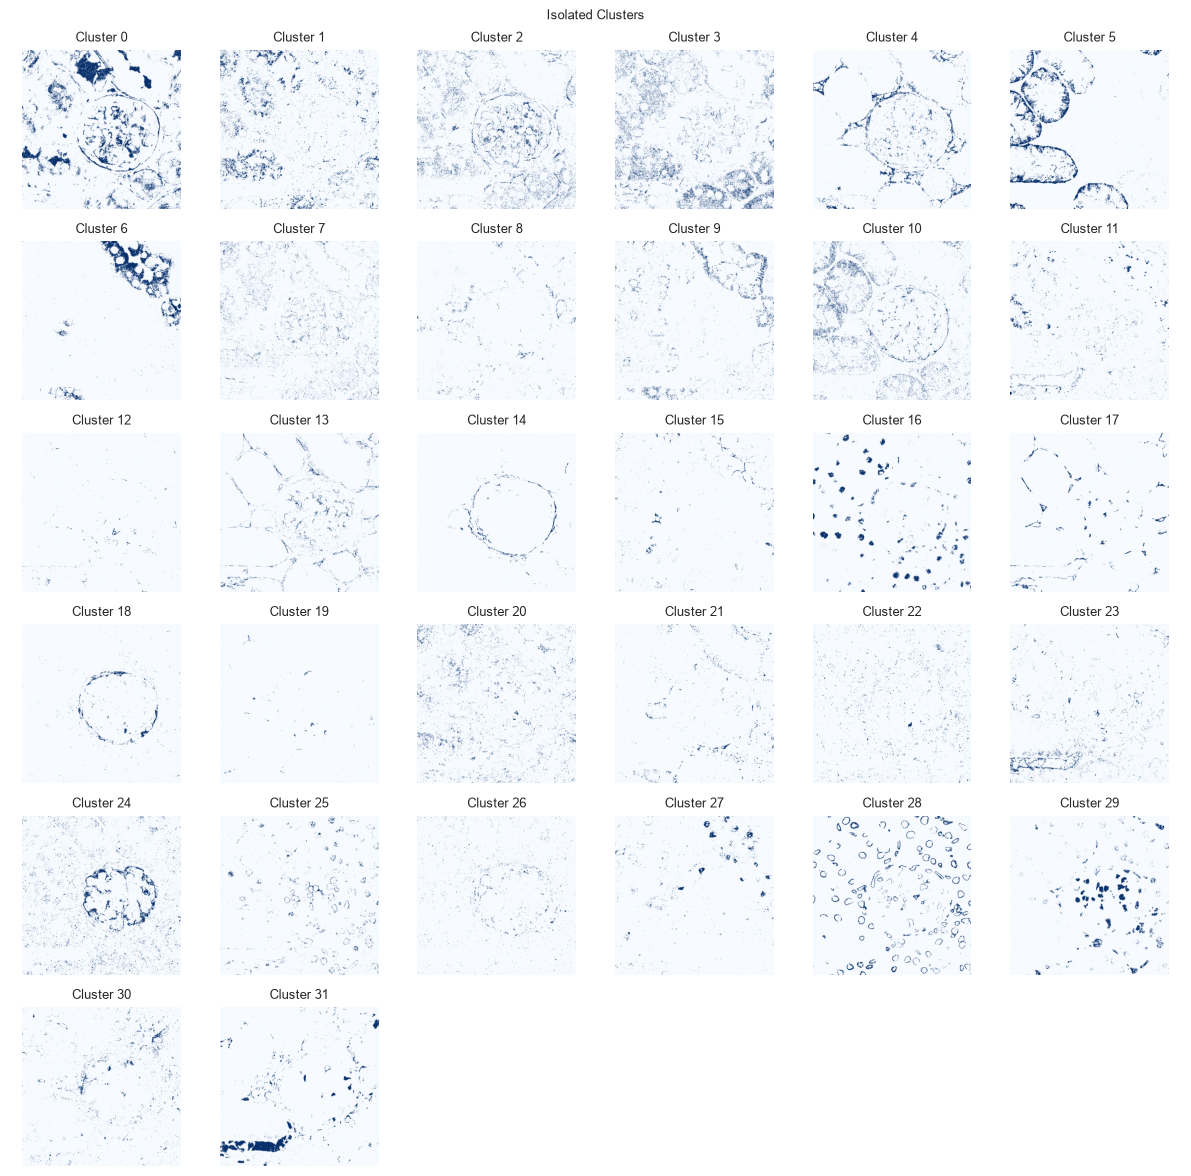

In [34]:
fig = so.plot.cluster_location(labelled_image)

## Differential abundance analysis


One of the main goals of `spatiomic` analyses is to generate a cluster abundance count matrix to perform differential cluster abundance analysis. First, we have to quantify the cluster abundance in each image (and if there are multiple images per sample, aggregate them per sample).


In [35]:
df_cluster_counts = so.tool.count_clusters(
    [f"./data/mouse_cgn/{image}-labelled.npy" for image in images],
    cluster_count=len(np.unique(communities)),
    normalize=True,
)

Since in this case we had two FOVs per sample, we need to aggregate the counts at the sample level.


In [36]:
df_cluster_counts["sample"] = [file_path.split("mouse_cgn/")[-1].split(" ")[0] for file_path in df_cluster_counts.index]
df_cluster_counts["disease"] = [is_disease[samples.index(sample)] for sample in df_cluster_counts["sample"]]
df_cluster_counts = df_cluster_counts.groupby("sample").mean()
df_cluster_counts.head()

,0,1,2,3,4,5,6,7,8,9,...,23,24,25,26,27,28,29,30,31,disease
sample,,,,,,,,,,,,,,,,,,,,,
245,0.136316,0.052944,0.060074,0.078749,0.046008,0.052985,0.026925,0.035907,0.010222,0.024455,...,0.023113,0.042143,0.023158,0.012985,0.011247,0.044551,0.036517,0.019384,0.029593,1.0
247,0.224548,0.052882,0.065318,0.065873,0.033044,0.040692,0.029905,0.021514,0.006753,0.031071,...,0.018169,0.024298,0.015530,0.020543,0.009895,0.049893,0.038692,0.013225,0.016680,1.0
248,0.097141,0.070312,0.046641,0.026511,0.070220,0.027002,0.011317,0.022376,0.007006,0.015966,...,0.014960,0.070907,0.020374,0.042290,0.038720,0.057878,0.030517,0.019796,0.018619,1.0
263,0.061221,0.019984,0.020753,0.033302,0.052310,0.056744,0.048345,0.018486,0.018465,0.020155,...,0.125983,0.032636,0.024584,0.026893,0.028042,0.021155,0.026904,0.029236,0.060946,0.0
265,0.105599,0.027961,0.027357,0.052165,0.053462,0.035660,0.036545,0.021524,0.021874,0.023605,...,0.073118,0.031260,0.014463,0.017610,0.021471,0.031884,0.042078,0.023835,0.094478,0.0


We can plot a PCA of the cluser abundances. Note the comparatively increased heterogeneity of the disease samples compared to the control samples.


(6, 2)


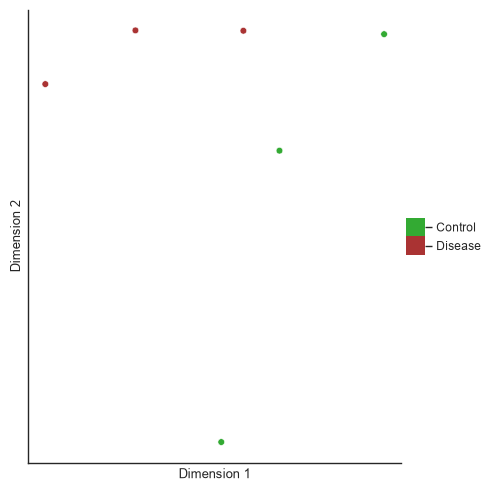

In [37]:
pca = so.dimension.pca(dimension_count=2, use_gpu=False)
pca_values = pca.fit_transform(df_cluster_counts.to_numpy()[:, :-1])
print(pca_values.shape)
condition = ["Disease" if disease else "Control" for disease in df_cluster_counts["disease"].to_numpy()]

fig = so.plot.cluster_scatter(
    pca_values,
    clusters=condition,
    colormap=ListedColormap(["#33AA33", "#AA3333"]),
    figsize=(5, 5),
)

The second PCA seems to differentiate the samples reasonably well and explains most of the variance seen in the cluster abundance data.


In [38]:
pca.get_explained_variance_ratio()

array([0.60600464, 0.23994224])

We can also plot the loadings of a dimension to see which clusters seem to be driving the separation.


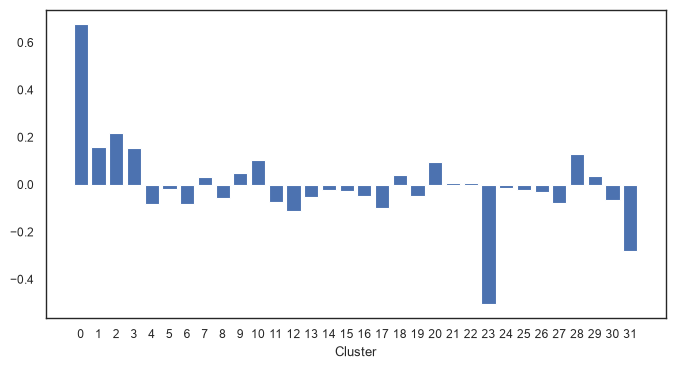

In [39]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(
    x=df_cluster_counts.columns[:-1].to_numpy().astype(np.uint8),
    height=pca.get_loadings()[0],
)
ax.set_xticks(df_cluster_counts.columns[:-1].to_numpy().astype(np.uint8))
ax.set_xlabel("Cluster")
plt.show()

The PCA plot already indicates differences between the disease and non-disease samples. We can visuallize differential cluster abundance with a volcano plot following statistical testing.


In [40]:
df_stats_abundance = so.tool.get_stats(
    df_cluster_counts.iloc[:, :-1].to_numpy(),
    group=df_cluster_counts["disease"].to_numpy(),
    channel_names=df_cluster_counts.columns,
    comparison=0,  # Choose your control group
    test="t",
    equal_variance=False,  # Use Welch's t-test
    dependent=False,
    correction=None,  # For larger sample sizes, you can use "fdr", "holm-sidak" or "bonferroni"
    test_kwargs={},
)

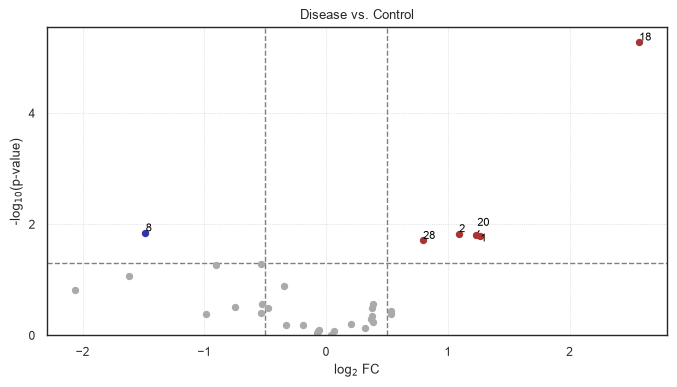

In [41]:
fig = so.plot.volcano(
    df_stats_abundance,
    channel_column="marker",
    title="Disease vs. Control",
    significant_log2_fold_change_threshold=0.5,
    figsize=(8, 4),
)
fig.set_dpi(100)

We can see, that even a downscaled analysis on two FOVs per sample already identifies the over-expression of phospho-c-Jun and Vimentin within the same pixels as a defining feature of the disease group.


In [42]:
df_stats_abundance_significantly_up = df_stats_abundance[
    (df_stats_abundance["p_value"] < 0.05) & (df_stats_abundance["log2_fold_change"] > 0.5)
].sort_values("log2_fold_change", ascending=False)
df_stats_abundance_significantly_up

,group,comparison,marker,p_value_corrected,log10_p_value_corrected,mean_group,mean_comparison,p_value,log10_p_value,ranksum,log2_fold_change
18,1.0,0.0,18,None,None,0.009072,0.001529,0.000005,5.279683,None,2.568337
1,1.0,0.0,1,None,None,0.058713,0.024474,0.016594,1.780044,None,1.262444
20,1.0,0.0,20,None,None,0.027931,0.011879,0.015955,1.797101,None,1.233405
2,1.0,0.0,2,None,None,0.057344,0.026946,0.014750,1.831196,None,1.089573
28,1.0,0.0,28,None,None,0.050774,0.029286,0.019532,1.709259,None,0.793891


In [43]:
for marker in df_stats_abundance_significantly_up["marker"]:
    df_stats_cluster = df_stats[df_stats["group"] == marker]
    df_stats_cluster_significant = df_stats_cluster[
        (df_stats_cluster["p_value"] < 0.05)
        & (df_stats_cluster["log2_fold_change"] > 0.5)
        & (df_stats_cluster["mean_group"] > 0.03)
    ].sort_values("log2_fold_change", ascending=False)

    print(f"Differentially abundant cluster {marker} consists of: " + ", ".join(df_stats_cluster_significant["marker"]))

Differentially abundant cluster 18 consists of: cjun, Vimentin, CD9, rab7, EEA1, ANXA, Podocin, SNP
Differentially abundant cluster 1 consists of: Lamp1, EEA1
Differentially abundant cluster 20 consists of: LMP7, CD9
Differentially abundant cluster 2 consists of: Podoplanin, PDGFR
Differentially abundant cluster 28 consists of: LaminB, DRAQ5, GR


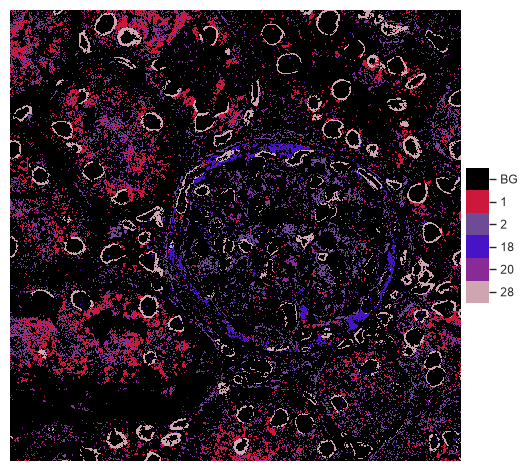

In [44]:
fig = so.plot.cluster_selection(
    labelled_image,
    clusters=df_stats_abundance_significantly_up["marker"].head(5).to_numpy(),
    colormap=colormap,
)

## Spatial analysis


Now we know which clusters are differentially abundant between groups, where they are located within images and what markers are driving them. But we can go a bit further and also evaluate which clusters are located near one another. First, we create a neighborhood offset with the radius of interest. This way, we can evaluate the spatial relationship at different distances. Here, we look at a queen neighborhood of 5 pixels.


In [45]:
neighborhood_offset = so.spatial.neighborhood_offset(
    neighborhood_type="queen",
    order=2,
    exclude_inner_order=0,  # note that 0, 0 will always be excluded
)

In [46]:
dfs_vicinity_composition = []

for image in tqdm(images):
    clustered_data = np.load(f"./data/mouse_cgn/{image}-labelled.npy")
    df_vicinity_composition = so.spatial.vicinity_composition(
        clustered_data,
        neighborhood_offset=neighborhood_offset,
        ignore_identities=True,
        ignore_repeated=True,
        use_gpu=False,
    )

    # include clusters that are absent from this image, so that rows and columns are indexed by all cluster ids
    cluster_ids = np.arange(np.max(communities) + 1)
    df_vicinity_composition = df_vicinity_composition.reindex(index=cluster_ids, columns=cluster_ids, fill_value=0)

    dfs_vicinity_composition.append(df_vicinity_composition)

dfs_vicinity_composition[0].head()

100%|██████████| 12/12 [00:14<00:00,  1.17s/it]


,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,0,2139,6323,8641,1133,443,77,4015,387,1033,...,282,243,1179,285,180,70,146,32,218,123
1,2411,0,2532,4646,394,1692,1539,1477,371,1439,...,614,600,1525,202,469,437,932,57,525,272
2,6128,2580,0,5391,2799,1062,95,1889,467,818,...,200,491,2567,428,372,69,303,78,437,240
3,9130,4279,5445,0,536,2827,148,2946,532,1545,...,325,1384,2012,305,364,59,280,33,245,505
4,899,414,3412,549,0,578,223,311,254,458,...,474,536,1023,390,403,196,712,268,572,978


We can combine the vicinity composition of individual images for the entire dataset and for each group.


In [47]:
df_vicinity_composition_overall = pd.concat(dfs_vicinity_composition).groupby(level=0).sum()

dfs_vicinity_composition_disease = [
    df for df, disease in zip(dfs_vicinity_composition, is_disease, strict=True) if disease
]
dfs_vicinity_composition_control = [
    df for df, disease in zip(dfs_vicinity_composition, is_disease, strict=True) if not disease
]

df_vicinity_composition_disease = pd.concat(dfs_vicinity_composition_disease).groupby(level=0).sum()
df_vicinity_composition_control = pd.concat(dfs_vicinity_composition_control).groupby(level=0).sum()

From this data, we can generate a vicinity graph and visualize it.


In [48]:
vicinity_graph = so.spatial.vicinity_graph(
    df_vicinity_composition_overall,
)

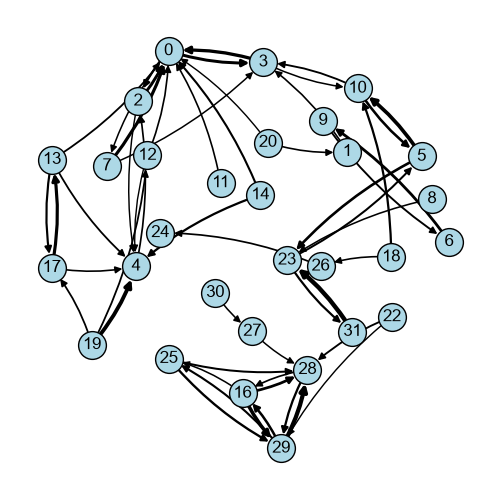

In [49]:
fig = so.plot.spatial_graph(
    vicinity_graph,
    edge_threshold=0.1,
)
fig.set_size_inches(5, 5)
fig.set_dpi(100)

We can already identify groups of heavily interconnected clusters. Nuclear signals, for example, should be located next to each other. Cluster ids can differ between machines, devices and software versions. Instead of hardcoding cluster ids, we therefore select the clusters by their marker profile: those with a significantly increased intensity of the nuclear stain DRAQ5. For each, we also calculate how much of its vicinity consists of the other selected clusters.

In [50]:
df_stats_draq5 = df_stats[
    (df_stats["marker"] == "DRAQ5") & (df_stats["p_value_corrected"] < 0.05) & (df_stats["log2_fold_change"] > 0.5)
]
clusters = df_stats_draq5["group"].to_numpy()

# the share of the vicinity of each selected cluster that consists of the other selected clusters
vicinity_share = df_vicinity_composition_overall.loc[clusters, clusters].sum(axis=1) / (
    df_vicinity_composition_overall.loc[clusters].sum(axis=1)
)
vicinity_share_expected = df_vicinity_composition_overall[clusters].to_numpy().sum() / (
    df_vicinity_composition_overall.to_numpy().sum()
)

for cluster in clusters:
    df_stats_cluster = df_stats[df_stats["group"] == cluster]
    df_stats_cluster_significant = df_stats_cluster[
        (df_stats_cluster["p_value_corrected"] < 0.05)
        & (np.abs(df_stats_cluster["log2_fold_change"]) > 0.5)
        & (np.abs(df_stats_cluster["mean_group"]) > 0.05)
    ].sort_values("log2_fold_change", ascending=False)

    print(
        f"Cluster {cluster} ({vicinity_share[cluster]:.0%} of its vicinity are other nuclear clusters) consists of: "
        + ", ".join(df_stats_cluster_significant["marker"])
    )

print(f"Expected share for clusters without spatial preference: {vicinity_share_expected:.0%}")

Cluster 16 (65% of its vicinity are other nuclear clusters) consists of: GR, DRAQ5, cjun
Cluster 22 (38% of its vicinity are other nuclear clusters) consists of: LMP7, LaminB, DRAQ5
Cluster 25 (44% of its vicinity are other nuclear clusters) consists of: GATA3, DRAQ5, Endomucin
Cluster 27 (30% of its vicinity are other nuclear clusters) consists of: DACH1, Calreticulin, p57, GATA3, ILR1A, DRAQ5, ANXA, LaminB
Cluster 28 (48% of its vicinity are other nuclear clusters) consists of: LaminB, DRAQ5
Cluster 29 (78% of its vicinity are other nuclear clusters) consists of: DRAQ5, GATA3, GR, LaminB
Expected share for clusters without spatial preference: 15%


A large share of the vicinity of each nuclear cluster consists of other nuclear clusters, more than expected without a spatial preference. We can confirm this in space again.

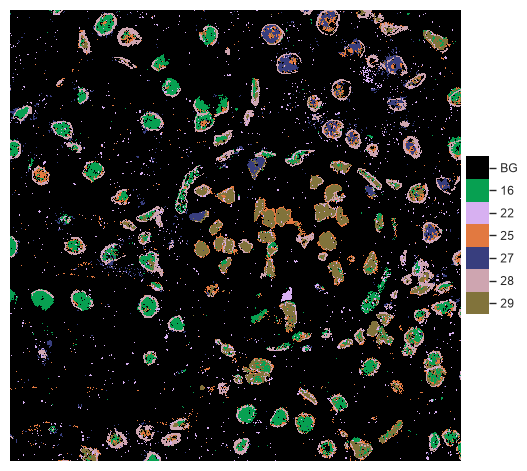

In [51]:
fig = so.plot.cluster_selection(
    labelled_image,
    clusters=clusters,
    colormap=colormap,
)

Now, let's evaluate the differences in cluster vicinities between groups.


In [52]:
vicinity_graph_disease = so.spatial.vicinity_graph(
    df_vicinity_composition_disease,
)

vicinity_graph_control = so.spatial.vicinity_graph(
    df_vicinity_composition_control,
)

The `spatial_graph` plotting function allows us to specify a reference graph. Increased connections are shown in red, decreased connections in blue.


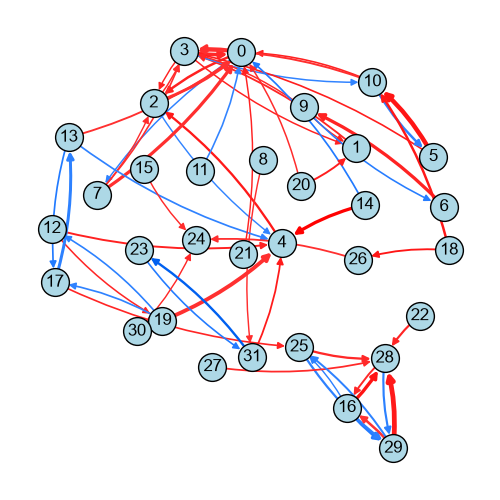

In [53]:
fig = so.plot.spatial_graph(
    vicinity_graph_disease,
    reference_graph=vicinity_graph_control,
    edge_threshold=0.1,
)
fig.set_size_inches(5, 5)
fig.set_dpi(100)

We can see that the connections between certain clusters increase in the disease group. We select the connection with the largest increase among those shown in the graph above.

In [54]:
df_edge_increases = pd.DataFrame(
    [
        {
            "origin": origin,
            "target": target,
            "increase": weight - vicinity_graph_control.edges[origin, target]["weight"],
            "weight_disease": weight,
            "weight_control": vicinity_graph_control.edges[origin, target]["weight"],
        }
        for origin, target, weight in vicinity_graph_disease.edges(data="weight")
        if vicinity_graph_control.has_edge(origin, target) and weight >= 0.1
    ]
).sort_values("increase", ascending=False, ignore_index=True)

# the markers that define each cluster, to judge the pairs biologically
df_stats_markers = df_stats[
    (df_stats["p_value_corrected"] < 0.05) & (df_stats["log2_fold_change"] > 0.5) & (df_stats["mean_group"] > 0.05)
].sort_values("log2_fold_change", ascending=False)
cluster_markers = df_stats_markers.groupby("group")["marker"].agg(", ".join)

df_edge_increases["origin_markers"] = df_edge_increases["origin"].map(cluster_markers).fillna("")
df_edge_increases["target_markers"] = df_edge_increases["target"].map(cluster_markers).fillna("")
df_edge_increases.head(10)

,origin,target,increase,weight_disease,weight_control,origin_markers,target_markers
0,14,4,0.162166,0.233995,0.071829,aSMAfitc,"PDGFR, Integrin-B1"
1,16,28,0.102833,0.241696,0.138863,"GR, DRAQ5, cjun","LaminB, DRAQ5"
2,5,10,0.096749,0.320220,0.223472,"OAT1, CD3",cjun
3,18,26,0.094625,0.134711,0.040086,"cjun, Vimentin, CD9","Vimentin, rab7, cjun, Nephrin, SNP, Podocin, A..."
4,18,10,0.089014,0.178094,0.089080,"cjun, Vimentin, CD9",cjun
5,4,2,0.084404,0.165542,0.081138,"PDGFR, Integrin-B1",
6,29,28,0.080180,0.342895,0.262715,"DRAQ5, GATA3, GR, LaminB","LaminB, DRAQ5"
7,31,4,0.079459,0.127980,0.048521,"CD3, prpS6, ZO1, DACH1, p57, 5MC, ANXA, Fibron...","PDGFR, Integrin-B1"
8,20,1,0.068412,0.138961,0.070549,LMP7,"Lamp1, EEA1"
9,5,3,0.068111,0.118736,0.050625,"OAT1, CD3",


In [55]:
pair_rank = 1
cluster_origin, cluster_target = df_edge_increases.loc[pair_rank, ["origin", "target"]]

In [56]:
for cluster in [cluster_origin, cluster_target]:
    df_stats_cluster = df_stats[df_stats["group"] == cluster]
    df_stats_cluster_significant = df_stats_cluster[
        (df_stats_cluster["p_value_corrected"] < 0.05)
        & (np.abs(df_stats_cluster["log2_fold_change"]) > 0.5)
        & (np.abs(df_stats_cluster["mean_group"]) > 0.05)
    ].sort_values("log2_fold_change", ascending=False)

    print(f"Cluster {cluster} consists of: " + ", ".join(df_stats_cluster_significant["marker"]))

Cluster 16 consists of: GR, DRAQ5, cjun
Cluster 28 consists of: LaminB, DRAQ5


We can evaluate the significance of these changes with a permutation test. Instead of reyling on the t-statistic or the t-test, we can define our own test statistic.


In [57]:
def compare_means(data, data_comparison, **kwargs):
    """Compare means of two groups."""
    return np.mean(data, axis=0) - np.mean(data_comparison, axis=0)


join_counts = np.expand_dims(
    np.array(
        [df.loc[cluster_origin, cluster_target] / df.loc[cluster_origin].sum() for df in dfs_vicinity_composition]
    ),
    axis=-1,
)

df_stats_vicinity = so.tool.get_stats(
    join_counts,
    group=is_disease,
    channel_names=["join_counts"],
    comparison=0,
    test=compare_means,
    dependent=False,
    correction=None,
    permutation_count=1000,
    permutation_seed=42,
)

In [58]:
df_stats_vicinity["p_value"]

0    0.008658
Name: p_value, dtype: float64

The p-value indicates whether the enrichment of pixels from the target cluster around pixels of the origin cluster differs between groups. Note that we selected this pair of clusters because its connection increased the most in the disease group, which biases the test towards small p-values. To test a spatial relationship rigorously, define it before looking at the data or select it on separate samples.

## Visualizing all clustered images


Now that we know which clusters are upregulated and what spatial relationships they have, we can visualize all images in the dataset with the cluster assignments.


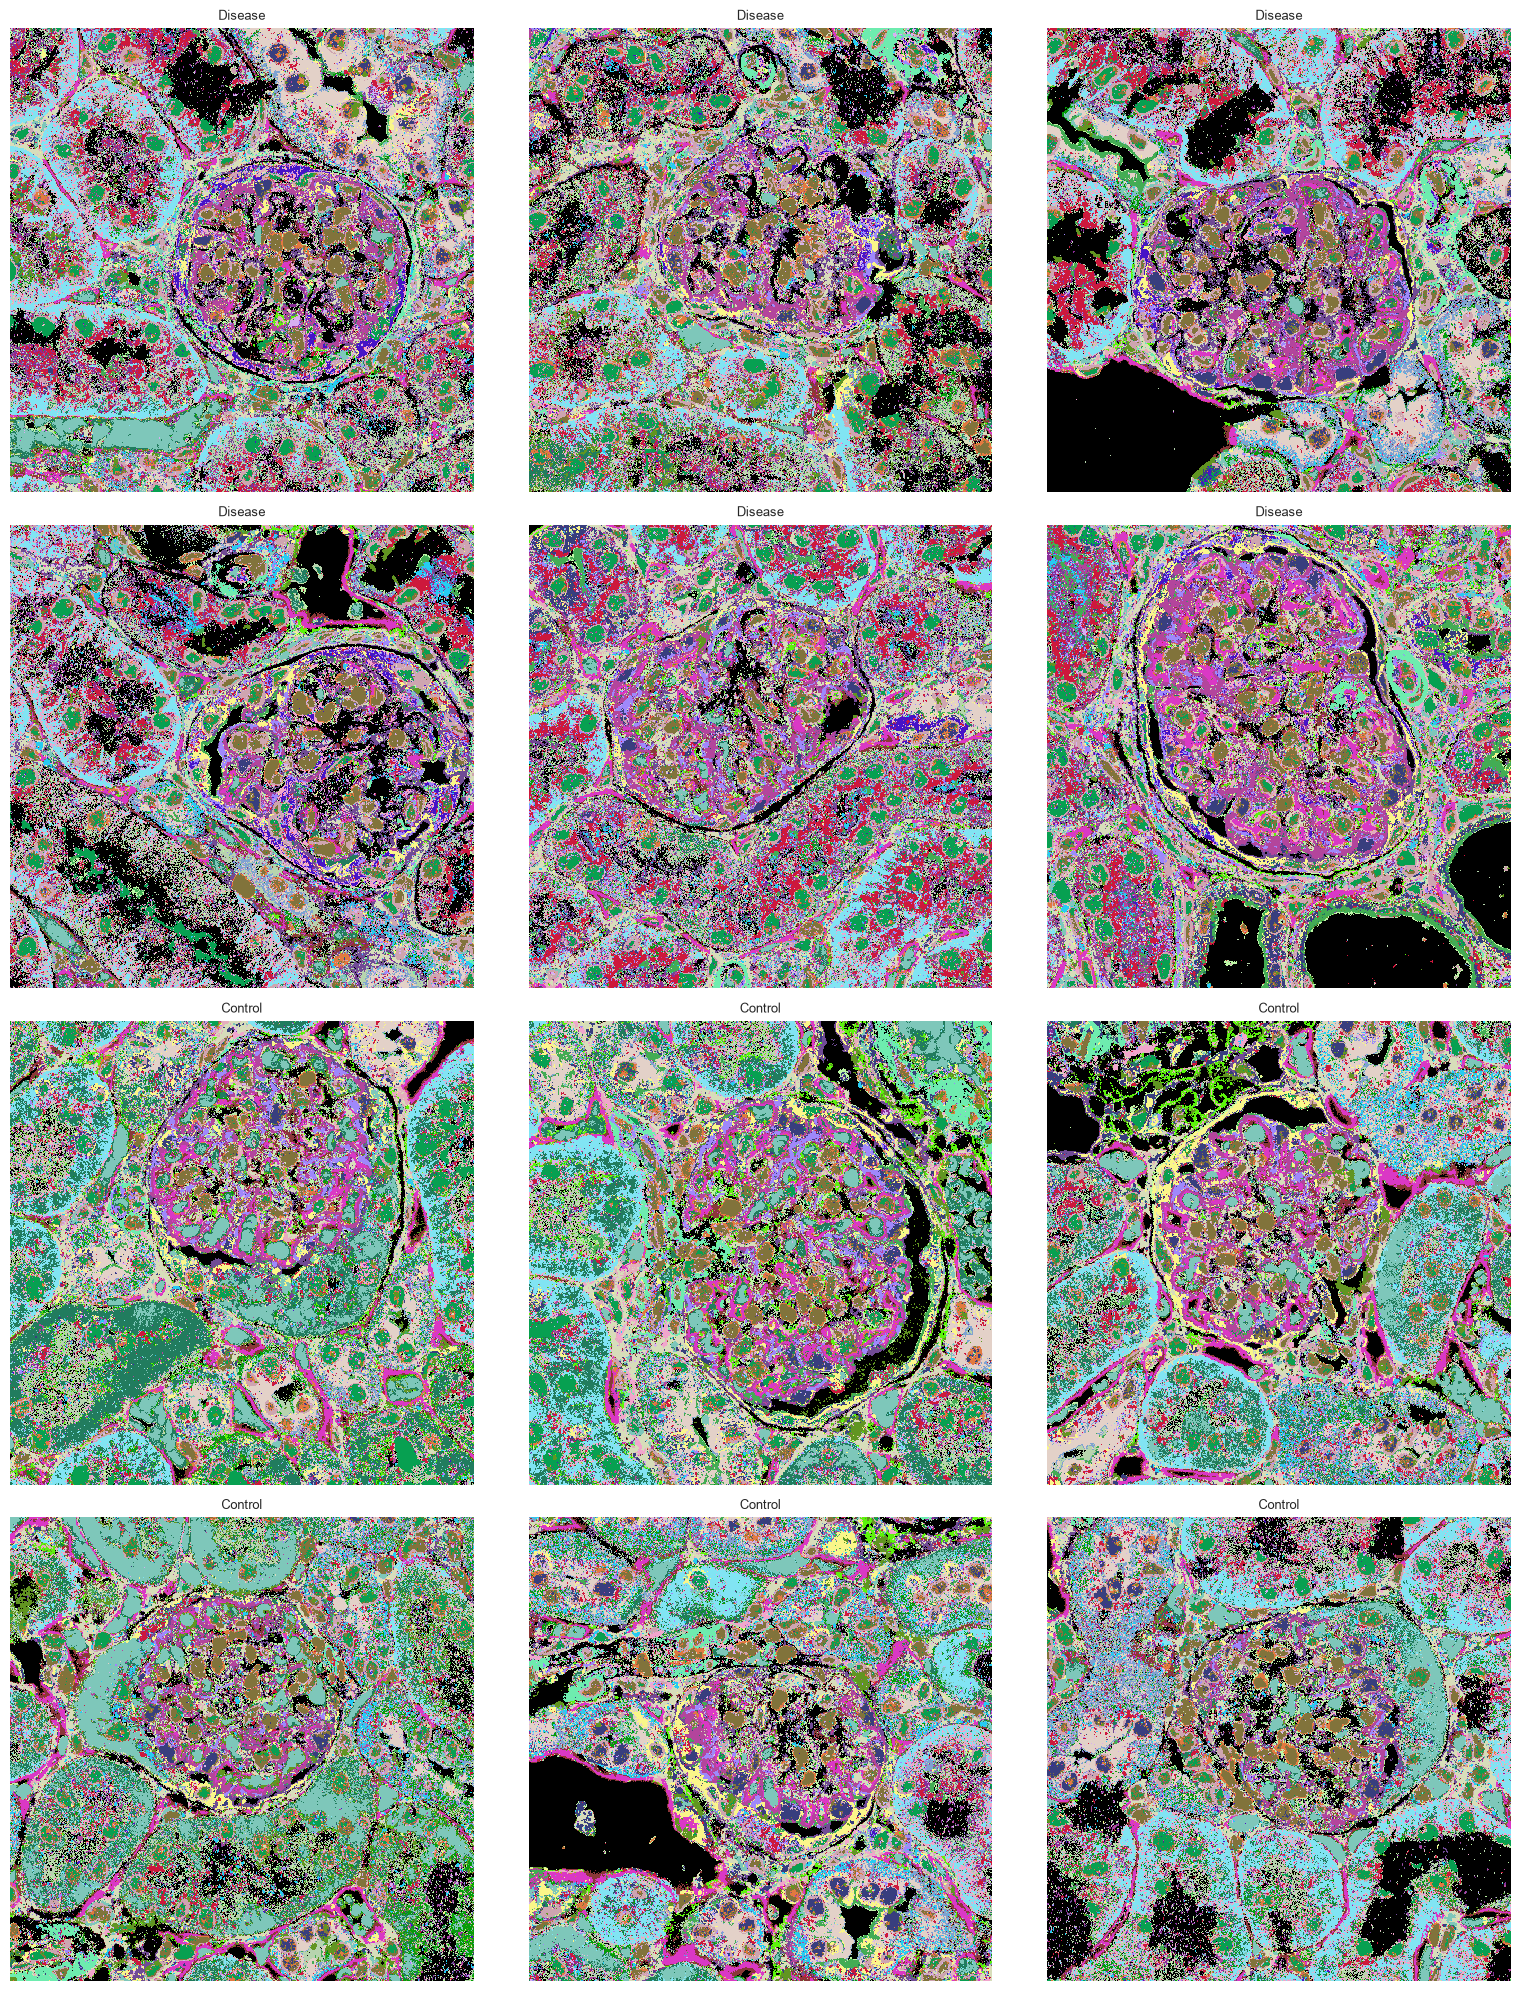

In [59]:
fig, axes = plt.subplots(4, 3, figsize=(16, 20))

for ax, image in zip(axes.flatten(), images, strict=True):
    ax = so.plot.cluster_image(
        np.load(f"./data/mouse_cgn/{image}-labelled.npy"),
        colormap=colormap,
        ax=ax,
        show_colorbar=False,
        title="Control" if not is_disease[images.index(image)] else "Disease",
    )

plt.tight_layout()

## Extended analyses


`spatiomic` builds upon fundamental data structures in the scientific Python ecosystem, e.g., NumPy arrays and pandas DataFrames. Many function also accept an `AnnData` object as input. Similarily, the `spatial` submodule of `spatiomic` largely relies on the `pysal` weights object. This allows for a seamless integration with other community tools, such as `esda` or `squidpy`. Please refer to the PathoPlex manuscript that first introduced the `spatiomic` package for example analyses using `spatiomic` output with `MistyR`, `PILOT`, `UnPaSt`, `Cellpose` and other tools.


E.g., based on the neighborhood offset generated above, we can create a spatial weights matrix for a given image to use with `pysal` and `esda`. For Python examples of `esda` for spatial analyses, please refer to the `pasta` spatial statistics guide for which we have contributed Python examples, specifically to all sections dealing with lattice-based data: [pasta spatial statistics guide](https://robinsonlabuzh.github.io/pasta/00-home.html).


In [60]:
spatial_weights = so.spatial.spatial_weights(
    data_shape=labelled_image.shape,
    neighborhood_offset=neighborhood_offset,
)

We can also easily convert each image to an `AnnData` object for use with `scverse®` tools.


In [61]:
adata = so.data.anndata_from_array(
    img_data_processed[-4],
    channel_names=channels,
    clusters=labelled_image,
    cluster_key="cluster",
    spatial_weights=spatial_weights,
)
adata

AnnData object with n_obs × n_vars = 765625 × 34
    obs: 'cluster'
    obsm: 'spatial'
    obsp: 'spatial_connectivities'
    layers: None (.X)

You can also refer to the spatial statistics tutorial included in this documentation for more examples of built-in methods and interoperability with `esda`. Please note that the spatial statistics functionality shown there is still actively developed, not fully covered by unittests and might change in the future.


## Time evaluation


Let's see how long it took to run this example. The time depends on your hardware, in particular on whether a GPU is available to train the self-organizing map.


In [62]:
time_end = get_time()
time_execution = time_end - time_start

print(f"Execution time: {time_execution:.2f} seconds")

Execution time: 95.73 seconds


## Session info


In [63]:
info = session_info(
    cpu=True,
    gpu=True,
)  # note that the output cannot be copied in the compiled docs version of this notebook
info

Package,Version
anndata,0.13.4
pandas,3.0.6
matplotlib,3.11.2
numpy,2.4.6
scikit-image,0.26.0
tqdm,4.70.1
spatiomic,0.11.0
requests,2.34.2
networkx,3.7
libpysal,4.15.1


For the online documentation, we can also print the session info as plain text.


In [64]:
for part in info._repr_mimebundle_()["text/markdown"].split("\n"):
    print(part)

| Package      | Version |
| ------------ | ------- |
| anndata      | 0.13.4  |
| pandas       | 3.0.6   |
| matplotlib   | 3.11.2  |
| numpy        | 2.4.6   |
| scikit-image | 0.26.0  |
| tqdm         | 4.70.1  |
| spatiomic    | 0.11.0  |
| requests     | 2.34.2  |
| networkx     | 3.7     |
| libpysal     | 4.15.1  |

| Dependency         | Version     |
| ------------------ | ----------- |
| lazy-loader        | 0.6         |
| patsy              | 1.0.3       |
| scikit-learn       | 1.9.1       |
| seaborn            | 0.13.2      |
| scverse-misc       | 0.1.7       |
| charset-normalizer | 3.5.2       |
| pyzmq              | 27.2.0      |
| tornado            | 6.6         |
| beautifulsoup4     | 4.15.0      |
| narwhals           | 2.27.1      |
| legacy-api-wrap    | 1.5         |
| pyparsing          | 3.3.3       |
| jupyter_client     | 8.10.0      |
| six                | 1.17.0      |
| pydantic-settings  | 2.16.1      |
| platformdirs       | 4.13.5      |
| numba  